# DATA SCIENCE INTERN @OASIS INFOBYTE

## AUTHOR : SHREENIDHI MEDAR

# Task 4 · Email Spam Detection with Machine Learning

# 1.Import necessary libraries

In [1]:
# Core libraries for data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Notebook settings

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Clean chart style and default chart size
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14

# Show charts inside the notebook
%matplotlib inline

## 2. Load the Dataset
The cell below finds the file automatically. If yours has a different name, set `DATA_FILE = 'your_file_name'`.

In [3]:
# Libraries for finding the file on disk
import os
import glob

# ---- Choose the data file ----
# Leave as None to auto-detect, or force a file: DATA_FILE = 'spam.csv'
DATA_FILE = None

CANDIDATES = ['spam.csv', 'SMSSpamCollection', 'SMSSpamCollection.txt', 'SMSSpamCollection.tsv', 'spam.txt']

if DATA_FILE is None:
    found = [f for f in CANDIDATES if os.path.isfile(f)]
    if not found:   # fall back to any file with "spam" in its name (ignoring notebooks, images, zips)
        found = sorted(f for f in glob.glob('*spam*')
                       if os.path.isfile(f) and not f.lower().endswith(('.ipynb', '.png', '.jpg', '.zip')))
    if not found:
        raise FileNotFoundError(
            "Dataset not found. Put spam.csv in the same folder as this notebook (or set DATA_FILE above)."
        )
    DATA_FILE = found[0]

print('Loading file:', DATA_FILE)

if DATA_FILE.lower().endswith('.csv'):
    # Kaggle version: comma separated, latin-1 encoded (this fixes the UnicodeDecodeError)
    raw = pd.read_csv(DATA_FILE, encoding='latin-1')
else:
    # UCI version: tab separated, no header row
    raw = pd.read_csv(DATA_FILE, sep='\t', header=None, names=['label', 'text'],
                      encoding='latin-1', quoting=3)

print('Raw shape:', raw.shape)
raw.head()

Loading file: spam.csv
Raw shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## 3. Data Inspection
Shape, column names, data types, null values and duplicates of the raw file.

In [4]:
print('Shape (rows, columns):', raw.shape)
print('Columns:', list(raw.columns))
raw.info()

Shape (rows, columns): (5572, 5)
Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [5]:
# Null value check and duplicate check
print('Missing values per column:')
print(raw.isnull().sum())
print('\nDuplicate rows:', int(raw.duplicated().sum()))

Missing values per column:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Duplicate rows: 403


## 4. Data Preparation and Class Distribution

### 4.1 Keep the label and text columns

In [6]:
# Different copies of the dataset name the columns differently, so map them to 'label' and 'text'
LABEL_NAMES = ('v1', 'category', 'label', 'class', 'type', 'target')
TEXT_NAMES = ('v2', 'message', 'text', 'sms', 'email', 'body', 'content')

col_map = {}
for col in raw.columns:
    name = str(col).strip().lower()
    if name in LABEL_NAMES and 'label' not in col_map.values():
        col_map[col] = 'label'
    elif name in TEXT_NAMES and 'text' not in col_map.values():
        col_map[col] = 'text'

df = raw.rename(columns=col_map)
if not {'label', 'text'}.issubset(df.columns):
    raise KeyError(f'Could not find label/text columns. Columns present: {list(raw.columns)}')

df = df[['label', 'text']].copy()          # drops the extra "Unnamed" columns
print('Shape after keeping 2 columns:', df.shape)
df.head()

Shape after keeping 2 columns: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### 4.2 Clean the labels, nulls and duplicates
Exact duplicate messages are removed **before** the train/test split. Otherwise the same message can land in both sets and make the scores look better than they really are.

In [7]:
rows_start = len(df)

# Remove rows with a missing label or message
df = df.dropna(subset=['label', 'text'])

# Make the labels consistent: lowercase, no stray spaces
df['label'] = df['label'].astype(str).str.strip().str.lower()
df['text'] = df['text'].astype(str).str.strip()

# Make sure we only have the two expected classes
unexpected = set(df['label'].unique()) - {'ham', 'spam'}
if unexpected:
    raise ValueError(f"Unexpected labels found: {unexpected}. Expected only 'ham' and 'spam'.")

# Remove exact duplicate messages
dups = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Numeric label for the models: ham = 0, spam = 1
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

print(f'Rows at start        : {rows_start}')
print(f'Duplicates removed   : {dups}')
print(f'Rows after cleaning  : {len(df)}')

Rows at start        : 5572
Duplicates removed   : 414
Rows after cleaning  : 5158


### 4.3 Class distribution (spam vs ham)

      Count  Percentage (%)
ham    4516           87.55
spam    642           12.45


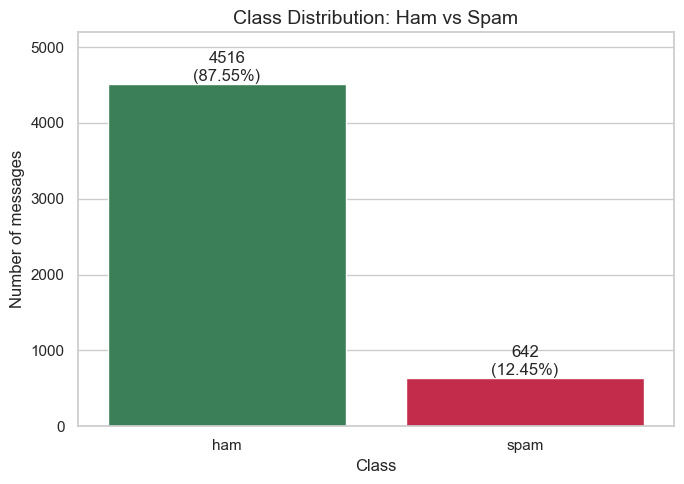


Baseline accuracy of always predicting ham: 87.55%


In [8]:
# Counts and percentages
counts = df['label'].value_counts()
percent = (df['label'].value_counts(normalize=True) * 100).round(2)
distribution = pd.DataFrame({'Count': counts, 'Percentage (%)': percent})
print(distribution)

# Bar chart with the count and percentage written on each bar
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=counts.index, y=counts.values, palette={'ham': 'seagreen', 'spam': 'crimson'}, ax=ax)
for i, label in enumerate(counts.index):
    ax.text(i, counts.values[i], f'{counts.values[i]}\n({percent[label]}%)', ha='center', va='bottom')
ax.set_title('Class Distribution: Ham vs Spam')
ax.set_xlabel('Class')
ax.set_ylabel('Number of messages')
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

# A "model" that always says ham would score this accuracy without detecting a single spam
baseline = counts['ham'] / counts.sum()
print(f'\nBaseline accuracy of always predicting ham: {baseline:.2%}')

### 4.4 Message length: do spam and ham look different?

label                ham   spam
char_count count  4516.0  642.0
           mean     70.4  137.6
           std      56.4   30.3
           min       2.0   13.0
           25%      34.0  131.2
           50%      52.0  148.0
           75%      90.0  157.0
           max     910.0  224.0
word_count count  4516.0  642.0
           mean     14.1   23.6
           std      11.1    6.0
           min       1.0    2.0
           25%       7.0   21.0
           50%      11.0   25.0
           75%      18.0   28.0
           max     171.0   35.0


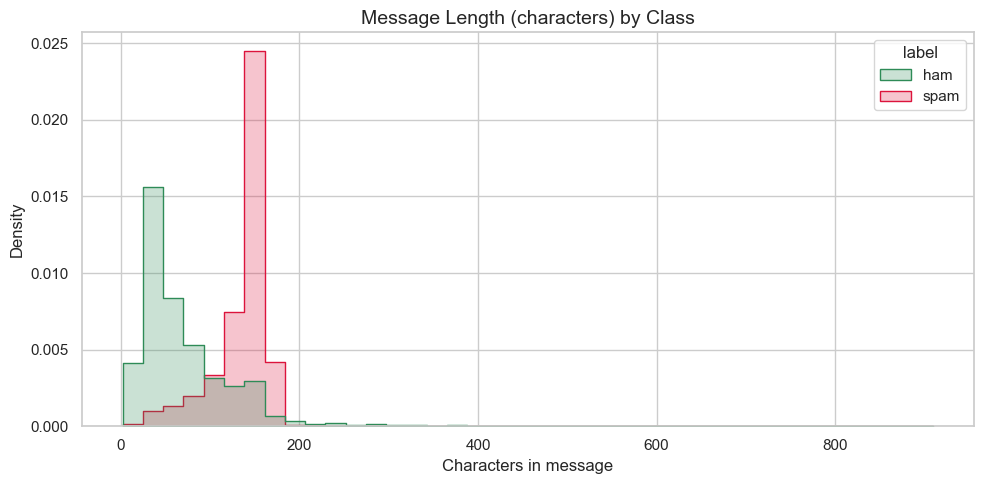

In [9]:
df['char_count'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

print(df.groupby('label')[['char_count', 'word_count']].describe().round(1).T)

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x='char_count', hue='label', bins=40, palette={'ham': 'seagreen', 'spam': 'crimson'},
             element='step', stat='density', common_norm=False, ax=ax)
ax.set_title('Message Length (characters) by Class')
ax.set_xlabel('Characters in message')
plt.tight_layout()
plt.show()

## 5. Text Pre-processing Pipeline
Raw text is messy. Before a model can learn from it, each message goes through these steps:

**Lowercase**,**Remove URLs**,**Tokenise**,**Remove stopwords**,**Stemming**

# 5.1 Import the text-processing libraries

In [10]:
import re
from collections import Counter

# NLTK gives us a stopword list and a stemmer. If NLTK is not installed (or the stopword download is
# blocked), we fall back to scikit-learn's built-in stopword list and skip stemming.
try:
    import nltk
    from nltk.stem import PorterStemmer
    from nltk.corpus import stopwords
    try:
        STOP_WORDS = set(stopwords.words('english'))
    except LookupError:
        nltk.download('stopwords', quiet=True)           # one-time download (needs internet)
        STOP_WORDS = set(stopwords.words('english'))
    stemmer = PorterStemmer()
    NLTK_OK = True
    print('NLTK stopwords and stemmer loaded.')
except Exception as err:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # fallback only
    STOP_WORDS = set(ENGLISH_STOP_WORDS)
    stemmer = None
    NLTK_OK = False
    print(f'NLTK not available ({type(err).__name__}). Using scikit-learn stopwords, no stemming.')
    print('To enable NLTK:  pip install nltk   then restart the kernel.')

print('Number of stopwords:', len(STOP_WORDS))

NLTK stopwords and stemmer loaded.
Number of stopwords: 179


### 5.2 The cleaning function

In [11]:
USE_STEMMING = True      # set to False to compare results without stemming

def clean_text(text):
    """Turn one raw message into a cleaned string of words."""
    text = text.lower()                                   # 1) lowercase
    text = re.sub(r'http\S+|www\.\S+', ' ', text)         # 2a) remove URLs
    text = re.sub(r'[^a-z0-9\s]', ' ', text)              # 2b) remove punctuation / special characters
    tokens = text.split()                                 # 3) tokenise (split into words)
    tokens = [t for t in tokens if t not in STOP_WORDS]   # 4) remove stopwords
    if USE_STEMMING and stemmer is not None:              # 5) optional stemming
        tokens = [stemmer.stem(t) for t in tokens]
    return ' '.join(tokens)

# Quick test on one message
sample = 'WINNER!! You have won a £1000 prize. Call 09061701461 now or visit www.claim.com!!!'
print('Before:', sample)
print('After :', clean_text(sample))

Before: WINNER!! You have won a £1000 prize. Call 09061701461 now or visit www.claim.com!!!
After : winner 1000 prize call 09061701461 visit


### 5.3 Apply it to every message

In [12]:
df['clean_text'] = df['text'].apply(clean_text)

# A few before/after examples
for label in ['ham', 'spam']:
    print(f'--- {label.upper()} examples ---')
    for _, row in df[df['label'] == label].head(3).iterrows():
        print('Before:', row['text'][:110])
        print('After :', row['clean_text'][:110])
        print()

# Some messages may become empty after cleaning (for example "ok ok ok"). Check how many.
empty = int((df['clean_text'].str.len() == 0).sum())
print('Messages that became empty after cleaning:', empty)

--- HAM examples ---
Before: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..
After : go jurong point crazi avail bugi n great world la e buffet cine got amor wat

Before: Ok lar... Joking wif u oni...
After : ok lar joke wif u oni

Before: U dun say so early hor... U c already then say...
After : u dun say earli hor u c alreadi say

--- SPAM examples ---
Before: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question
After : free entri 2 wkli comp win fa cup final tkt 21st may 2005 text fa 87121 receiv entri question std txt rate c a

Before: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb o
After : freemsg hey darl 3 week word back like fun still tb ok xxx std chg send 1 50 rcv

Before: WINNER!! As a valued network customer you have been selected to receivea å£900 prize reward! To claim call 090
After : winne

## 6. Most Common Words and WordClouds 
Which words are typical for spam and which for ham? Bar charts first (always work), then WordClouds.

### 6.1 Top words per class

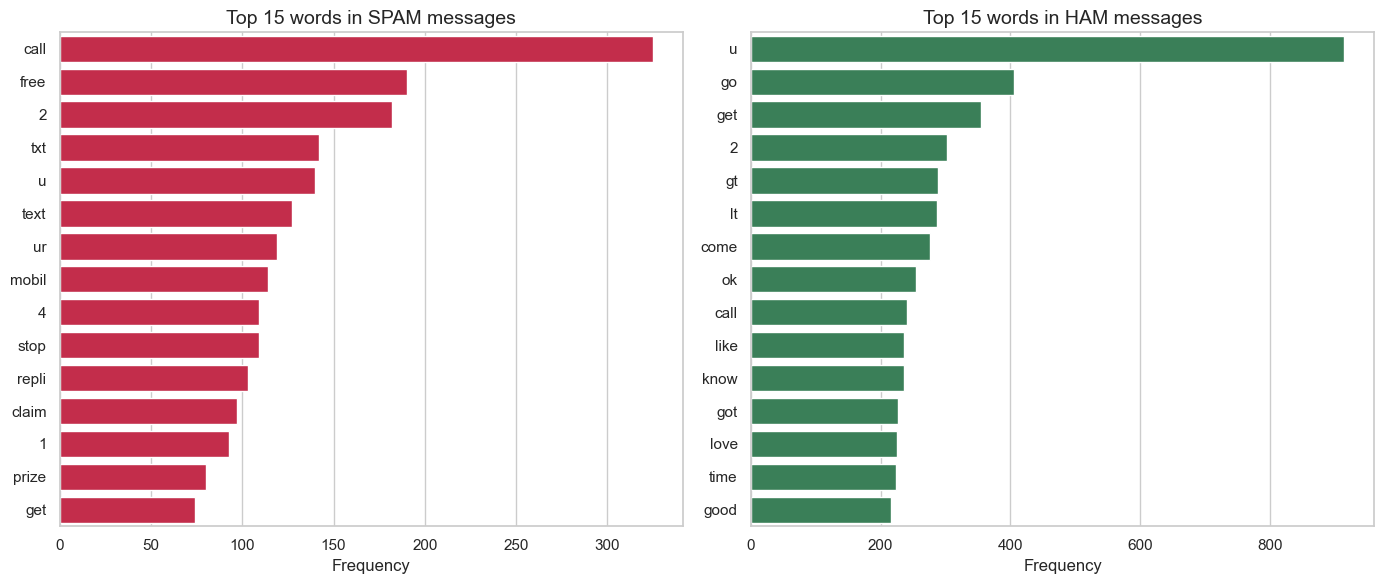

In [13]:
def top_words(label, n=15):
    """Most frequent words in the cleaned messages of one class."""
    words = ' '.join(df.loc[df['label'] == label, 'clean_text']).split()
    return Counter(words).most_common(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, label, color in zip(axes, ['spam', 'ham'], ['crimson', 'seagreen']):
    words, freq = zip(*top_words(label))
    sns.barplot(x=list(freq), y=list(words), color=color, ax=ax)
    ax.set_title(f'Top 15 words in {label.upper()} messages')
    ax.set_xlabel('Frequency')
plt.tight_layout()
plt.show()

### 6.2 WordClouds
A WordCloud draws frequent words bigger. It needs the `wordcloud` package (`pip install wordcloud`).

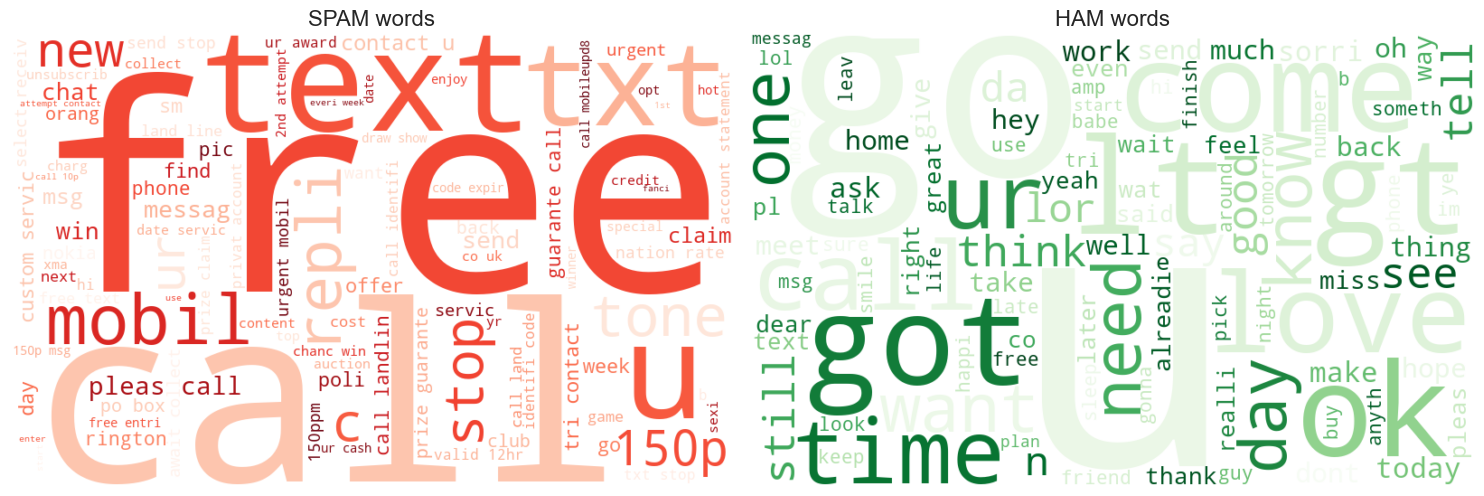

In [14]:
try:
    from wordcloud import WordCloud
    WORDCLOUD_OK = True
except ImportError:
    WORDCLOUD_OK = False
    print('The wordcloud package is not installed, so the WordClouds are skipped (the bar charts above show the same idea).')
    print('To enable them:  pip install wordcloud   then restart the kernel and run all cells again.')

if WORDCLOUD_OK:
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, label, cmap in zip(axes, ['spam', 'ham'], ['Reds', 'Greens']):
        text = ' '.join(df.loc[df['label'] == label, 'clean_text'])
        cloud = WordCloud(width=800, height=500, background_color='white',
                          colormap=cmap, max_words=100, random_state=42).generate(text)
        ax.imshow(cloud, interpolation='bilinear')
        ax.set_title(f'{label.upper()} words', fontsize=16)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

**Observation (check against your own charts):** spam is typically dominated by *call-to-action and money words* (free, win, prize, claim, urgent, call, txt, reply, cash, mobile). Ham is dominated by *everyday conversation words* (come, home, love, going, time, ok, know). These very different vocabularies are exactly what the classifier learns to separate.

## 7. Train/Test Split

In [15]:
# Machine learning library: splitting the data
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['label_num']
)

X_train, y_train = train_df['clean_text'], train_df['label_num']
X_test, y_test = test_df['clean_text'], test_df['label_num']

print('Training messages:', len(X_train), '| spam share: {:.2%}'.format(y_train.mean()))
print('Test messages    :', len(X_test), '| spam share: {:.2%}'.format(y_test.mean()))

Training messages: 4126 | spam share: 12.46%
Test messages    : 1032 | spam share: 12.40%


## 8. Feature Extraction with TF-IDF

In [16]:
# Machine learning library: TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

# fit_transform on TRAIN: learns the vocabulary and IDF values, then converts text to numbers
X_train_tfidf = tfidf.fit_transform(X_train)

# transform on TEST: uses the vocabulary learned from the training set only
X_test_tfidf = tfidf.transform(X_test)

print('Training matrix shape:', X_train_tfidf.shape, '(messages x features)')
print('Test matrix shape    :', X_test_tfidf.shape)
print('Vocabulary size      :', len(tfidf.get_feature_names_out()))

Training matrix shape: (4126, 5760) (messages x features)
Test matrix shape    : (1032, 5760)
Vocabulary size      : 5760


In [17]:
# Which words does TF-IDF consider most "weighty" across the training set? (highest average score)
mean_scores = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
terms = tfidf.get_feature_names_out()
top_idx = mean_scores.argsort()[::-1][:15]
pd.DataFrame({'Term': terms[top_idx], 'Mean TF-IDF': mean_scores[top_idx].round(4)}).reset_index(drop=True)

,Term,Mean TF-IDF
0,call,0.0155
1,go,0.0153
2,get,0.0148
3,ok,0.0144
4,come,0.0125
5,know,0.0106
6,like,0.0104
7,time,0.0101
8,ur,0.0099
9,want,0.0096


## 9. Train the Classifiers

### 9.1 Import the classifiers
Three models are trained:
- **Multinomial Naive Bayes**
- **Logistic Regression**
- **Linear SVM (LinearSVC)**

In [18]:
# The classifiers
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

### 9.2 Train every model on the training set
`class_weight='balanced'` tells Logistic Regression and the SVM to treat a missed spam as more costly, which helps with the class imbalance.

In [19]:
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=0.1),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Linear SVM': LinearSVC(class_weight='balanced', random_state=42),
}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    print('Trained:', name)

Trained: Multinomial Naive Bayes
Trained: Logistic Regression
Trained: Linear SVM


### 9.3 What did Naive Bayes learn? The most spam-like and most ham-like words

In [20]:
nb = models['Multinomial Naive Bayes']
# Difference of the log-probabilities of each word in spam vs ham: big positive = strongly spam-like
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
order = log_ratio.argsort()

top_spam = pd.Series(terms[order[::-1][:15]], name='Most spam-like words')
top_ham = pd.Series(terms[order[:15]], name='Most ham-like words')
pd.concat([top_spam, top_ham], axis=1)

,Most spam-like words,Most ham-like words
0,claim,gt
1,prize,lt
2,tone,lt gt
3,150p,lor
4,rington,da
5,nokia,say
6,guarante,lol
7,18,later
8,16,sure
9,cs,anyth


## 10. Evaluate the Models
Every model is scored on the **test set** (messages it has never seen).

### 10.1 Import the evaluation metrics

In [21]:
# Metrics used to judge the models
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

### 10.2 Accuracy, precision, recall, F1 and classification report

In [22]:
test_results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred
    test_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (spam)': precision_score(y_test, y_pred),
        'Recall (spam)': recall_score(y_test, y_pred),
        'F1 (spam)': f1_score(y_test, y_pred),
    })

    print('=' * 62)
    print(name)
    print('=' * 62)
    print(classification_report(y_test, y_pred, target_names=['ham', 'spam'], digits=3))

results = pd.DataFrame(test_results).set_index('Model').round(4)
results

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham      0.984     0.996     0.990       904
        spam      0.966     0.883     0.922       128

    accuracy                          0.982      1032
   macro avg      0.975     0.939     0.956      1032
weighted avg      0.981     0.982     0.981      1032

Logistic Regression
              precision    recall  f1-score   support

         ham      0.990     0.987     0.988       904
        spam      0.908     0.930     0.919       128

    accuracy                          0.980      1032
   macro avg      0.949     0.958     0.954      1032
weighted avg      0.980     0.980     0.980      1032

Linear SVM
              precision    recall  f1-score   support

         ham      0.990     0.996     0.993       904
        spam      0.967     0.930     0.948       128

    accuracy                          0.987      1032
   macro avg      0.979     0.963     0.971      1032
weighted avg      0

,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
Multinomial Naive Bayes,0.9816,0.9658,0.8828,0.9224
Logistic Regression,0.9797,0.9084,0.9297,0.9189
Linear SVM,0.9874,0.9675,0.9297,0.9482


### 10.3 Confusion matrices

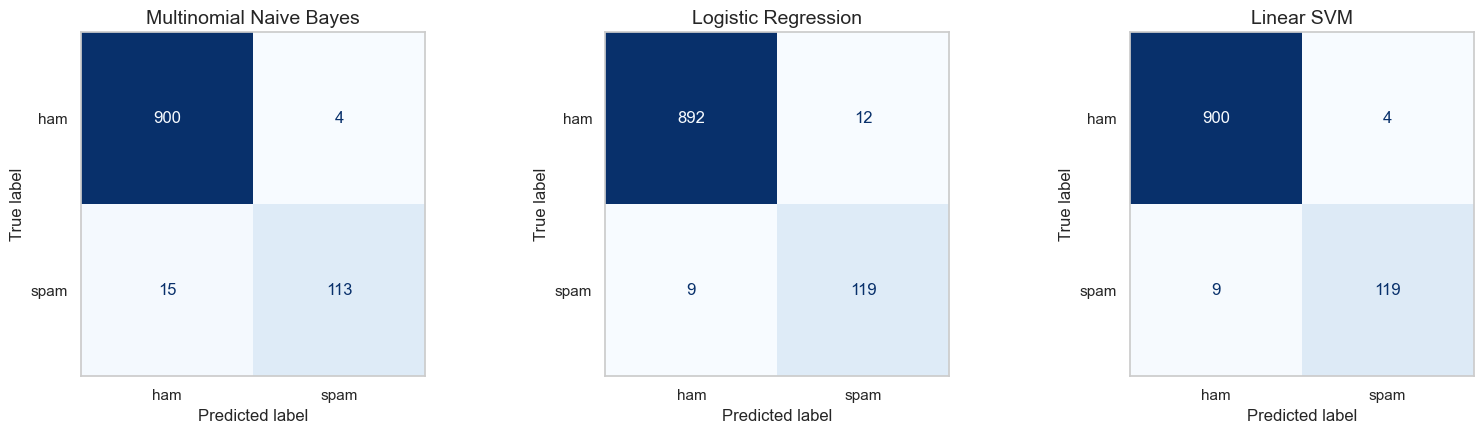

Multinomial Naive Bayes    spam caught:  113 | spam missed (FN):  15 | ham wrongly flagged (FP):   4
Logistic Regression        spam caught:  119 | spam missed (FN):   9 | ham wrongly flagged (FP):  12
Linear SVM                 spam caught:  119 | spam missed (FN):   9 | ham wrongly flagged (FP):   4


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['ham', 'spam']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

# Spelled out in numbers
for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f'{name:26s} spam caught: {tp:4d} | spam missed (FN): {fn:3d} | ham wrongly flagged (FP): {fp:3d}')

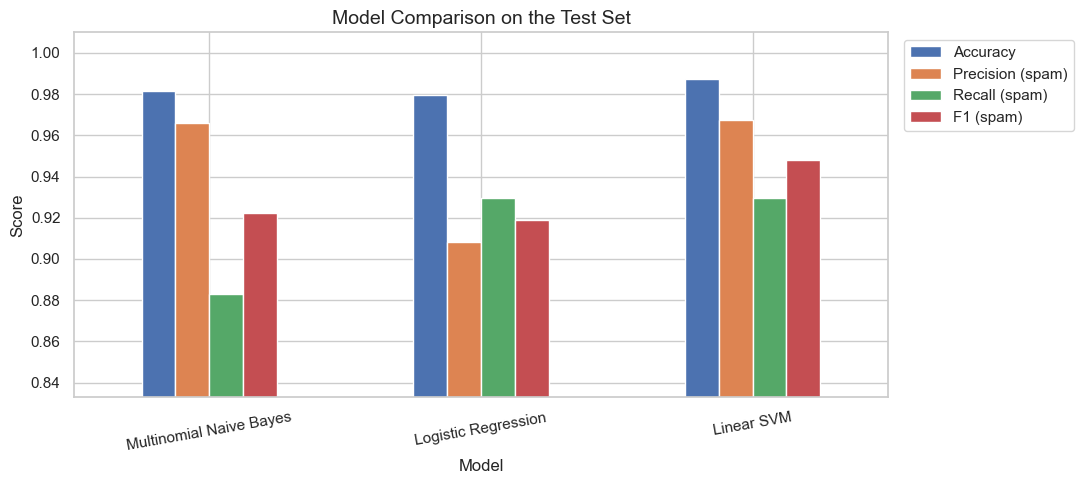

In [24]:
# Side-by-side comparison of the four metrics
results.plot(kind='bar', figsize=(11, 5), rot=10)
plt.ylim(max(0, results.values.min() - 0.05), 1.01)
plt.ylabel('Score')
plt.title('Model Comparison on the Test Set')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))   # legend outside the plot so it hides no bars
plt.tight_layout()
plt.show()

**Reading the results:** compare the *Recall (spam)* and *Precision (spam)* columns, not just Accuracy. Remember the baseline: a model that never detects spam still gets a high accuracy on this imbalanced data. The test set also contains relatively few spam messages, so a single missed spam changes recall noticeably. The cross-validation in the next section gives a steadier comparison.

## 11. Cross-Validation and Best Model

In [25]:
# Cross-validation tools
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'accuracy': 'accuracy'}

cv_rows = []
for name, model in models.items():
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), clone(model))
    scores = cross_validate(pipe, df['clean_text'], df['label_num'], cv=cv, scoring=scoring)
    cv_rows.append({
        'Model': name,
        'CV Accuracy': scores['test_accuracy'].mean(),
        'CV Precision (spam)': scores['test_precision'].mean(),
        'CV Recall (spam)': scores['test_recall'].mean(),
        'CV F1 (spam)': scores['test_f1'].mean(),
        'CV F1 Std': scores['test_f1'].std(),
    })

cv_results = pd.DataFrame(cv_rows).set_index('Model').round(4)
cv_results

,CV Accuracy,CV Precision (spam),CV Recall (spam),CV F1 (spam),CV F1 Std
Model,,,,,
Multinomial Naive Bayes,0.9827,0.9791,0.8801,0.9266,0.0221
Logistic Regression,0.9734,0.8774,0.9160,0.8952,0.0244
Linear SVM,0.9826,0.9487,0.9098,0.9279,0.0255


### Declare the best model

In [26]:
ranked = cv_results.sort_values(['CV F1 (spam)', 'CV Recall (spam)', 'CV F1 Std'],
                                ascending=[False, False, True])
best_name = ranked.index[0]
best_model = models[best_name]

print(f'BEST MODEL: {best_name}\n')
print(ranked.loc[best_name].to_string())
gap = ranked['CV F1 (spam)'].max() - ranked['CV F1 (spam)'].min()
print(f'\nGap between best and worst model (CV F1): {gap * 100:.2f} percentage points')
ranked

BEST MODEL: Linear SVM

CV Accuracy            0.9826
CV Precision (spam)    0.9487
CV Recall (spam)       0.9098
CV F1 (spam)           0.9279
CV F1 Std              0.0255

Gap between best and worst model (CV F1): 3.27 percentage points


,CV Accuracy,CV Precision (spam),CV Recall (spam),CV F1 (spam),CV F1 Std
Model,,,,,
Linear SVM,0.9826,0.9487,0.9098,0.9279,0.0255
Multinomial Naive Bayes,0.9827,0.9791,0.8801,0.9266,0.0221
Logistic Regression,0.9734,0.8774,0.9160,0.8952,0.0244


### 12. Where does the best model still make mistakes?
Looking at the actual errors is the best way to understand a model's limits.

In [27]:
best_pred = best_model.predict(X_test_tfidf)
errors = test_df.assign(predicted=best_pred)

false_neg = errors[(errors['label_num'] == 1) & (errors['predicted'] == 0)]
false_pos = errors[(errors['label_num'] == 0) & (errors['predicted'] == 1)]

print(f'{best_name}: {len(false_neg)} spam missed, {len(false_pos)} ham wrongly flagged\n')

print('--- SPAM that was MISSED (false negatives) ---')
for t in false_neg['text'].head(5):
    print('*', t[:150])

print('\n--- HAM that was WRONGLY FLAGGED as spam (false positives) ---')
for t in false_pos['text'].head(5):
    print('*', t[:150])

Linear SVM: 9 spam missed, 4 ham wrongly flagged

--- SPAM that was MISSED (false negatives) ---
* Sorry I missed your call let's talk when you have the time. I'm on 07090201529
* LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better? Why not send a video in a MMSto 
* Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msg
* \For the most sparkling shopping breaks from 45 per person; call 0121 2025050 or visit www.shortbreaks.org.uk\""
* thesmszone.com lets you send free anonymous and masked messages..im sending this message from there..do you see the potential for abuse???

--- HAM that was WRONGLY FLAGGED as spam (false positives) ---
* K.:)you are the only girl waiting in reception ah?
* Send me the new number
* Did u receive my msg?
* K k:) sms chat with me.


## 13. Try It on New Messages
Any new message must go through the **same steps**: clean the text, then the *already fitted* TF-IDF, then the model.

In [28]:
def predict_message(message, model=best_model):
    """Classify one new message as SPAM or HAM using the full pipeline."""
    cleaned = clean_text(message)                 # same cleaning as the training data
    features = tfidf.transform([cleaned])         # fitted TF-IDF (transform only, never fit again)
    label = model.predict(features)[0]
    return 'SPAM' if label == 1 else 'HAM'

new_messages = [
    'WINNER!! You have been selected for a free £1000 prize. Call 09061701461 now to claim!',
    'Hey, are we still meeting for lunch tomorrow? Let me know what time works.',
    'URGENT: your account is suspended. Click http://secure-login.example.com to verify now',
    'Can you send me the notes from the lecture? I missed the last ten minutes.',
    'Congratulations! Reply YES to receive your free ringtone. Text STOP to opt out.',
]

print(f'Model used: {best_name}\n')
for msg in new_messages:
    print(f'[{predict_message(msg):4s}]  {msg}')

Model used: Linear SVM

[SPAM]  WINNER!! You have been selected for a free £1000 prize. Call 09061701461 now to claim!
[HAM ]  Hey, are we still meeting for lunch tomorrow? Let me know what time works.
[SPAM]  URGENT: your account is suspended. Click http://secure-login.example.com to verify now
[HAM ]  Can you send me the notes from the lecture? I missed the last ten minutes.
[SPAM]  Congratulations! Reply YES to receive your free ringtone. Text STOP to opt out.


# THANK YOU